# AirSense – Hyderabad Air Quality Analysis and AQI Prediction
## End-to-End Data Analytics & Machine Learning Pipeline

**Author:** AirSense Development Team  
**Focus City:** Hyderabad, Telangana, India  
**Target:** Daily Air Quality Index (AQI) Analysis and Prediction  

---
### Notebook Structure & Roadmap:
- **Phase 1 & 2 (Foundations):** Raw Dataset Loading, Initial Hyderabad Filtering & Temporal Quality Inspection.
- **Phase 3 (Data Cleaning):** Causality-Preserving Imputation (`ffill` limit=3), IQR Outlier Audit, and Cleaned Dataset Export (`dataset/hyderabad_aqi_cleaned.csv`).
- **Phase 4 (Current Phase):** Exploratory Data Analysis (EDA), Statistical Distributions, Temporal Trends, Pollutant Interactions, and Matplotlib Visualizations.
- **Phase 5 (Upcoming):** Chronological ML Train/Test Split, Lag Feature Engineering, and Random Forest Regression.
- **Phase 6 (Upcoming):** Streamlit Web Application Dashboard Integration.


## 1. Environment Setup & Library Imports
We use only beginner-friendly, standard libraries:
- `pandas` for data manipulation and time-series aggregation.
- `numpy` for mathematical calculations.
- `matplotlib.pyplot` for creating and saving clean, accessible visualizations without relying on Seaborn.
- `src.preprocessing` for data cleaning functions.


In [1]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Add project root to sys.path so we can import reusable modules from src
project_root = os.path.abspath('..')
if project_root not in sys.path:
    sys.path.append(project_root)

# Import reusable preprocessing functions
from src.preprocessing import load_data, check_missing_values

# Configure display formatting and ensure visualizations directory exists
pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 1000)
pd.set_option('display.float_format', lambda x: '%.2f' % x)

os.makedirs('../visualizations', exist_ok=True)
print("Libraries imported and visualizations directory ready.")


Libraries imported and visualizations directory ready.


## 2. Load the Cleaned Hyderabad Dataset
We load the verified, cleaned dataset `dataset/hyderabad_aqi_cleaned.csv` prepared during Phase 3.
All dates are parsed into `datetime` format and ordered chronologically.


In [2]:
cleaned_filepath = '../dataset/hyderabad_aqi_cleaned.csv'
df = pd.read_csv(cleaned_filepath)
df['Date'] = pd.to_datetime(df['Date'])

print(f"Cleaned dataset loaded successfully from: {cleaned_filepath}")
print(f"Shape: {df.shape[0]} rows, {df.shape[1]} columns")
print(f"Date Range: {df['Date'].min().strftime('%Y-%m-%d')} to {df['Date'].max().strftime('%Y-%m-%d')}")
display(df.head(3))


Cleaned dataset loaded successfully from: ../dataset/hyderabad_aqi_cleaned.csv
Shape: 2006 rows, 16 columns
Date Range: 2015-01-04 to 2020-07-01


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Hyderabad,2015-01-04,NaN,NaN,3.70,17.19,20.89,NaN,0.30,2.58,30.34,0.41,6.15,1.11,NaN,NaN
1,Hyderabad,2015-01-05,NaN,NaN,3.61,9.69,13.30,NaN,0.23,5.19,31.28,0.39,7.22,0.55,NaN,NaN
2,Hyderabad,2015-01-06,NaN,NaN,4.21,22.02,26.23,NaN,0.31,9.09,28.56,0.52,5.14,0.53,NaN,NaN


---
# Phase 4: Exploratory Data Analysis (EDA) and Visualization

In this phase, we analyze the underlying patterns of Hyderabad's air pollution:
1. **Basic Statistical Analysis:** Descriptive statistics of AQI, PM2.5, PM10, yearly and monthly breakdowns.
2. **AQI Trend Analysis:** Daily variation and monthly aggregated patterns over 5.5 years.
3. **Pollutant Analysis:** Trend lines for PM2.5, PM10, coarse-vs-fine particulate comparison, and average pollutant concentration rankings.
4. **AQI Category Distribution:** Categorical breakdown based on CPCB health standards.
5. **Correlation Analysis:** Pearson correlation matrix and a pure Matplotlib heatmap to identify key drivers of AQI.
6. **Data-Driven Insights:** Comprehensive factual summary derived directly from the empirical results.


### Task 1: Basic Statistical Analysis
We calculate the statistical metrics for AQI and key particulate pollutants.
*Note:* As established in Phase 3, 126 unmonitored days have missing AQI; only valid observations are included in target statistics.


In [3]:
# 1. Calculate mean, median, minimum, and maximum AQI on valid observations
df_aqi_valid = df.dropna(subset=['AQI']).copy()

aqi_mean = df_aqi_valid['AQI'].mean()
aqi_median = df_aqi_valid['AQI'].median()
aqi_min = df_aqi_valid['AQI'].min()
aqi_max = df_aqi_valid['AQI'].max()

# 2. Calculate mean and median for PM2.5 and PM10
pm25_mean = df['PM2.5'].mean()
pm25_median = df['PM2.5'].median()
pm10_mean = df['PM10'].mean()
pm10_median = df['PM10'].median()

# 3. Find highest and lowest AQI dates
min_row = df_aqi_valid.loc[df_aqi_valid['AQI'].idxmin()]
max_row = df_aqi_valid.loc[df_aqi_valid['AQI'].idxmax()]

# Display Summary Table
stats_overview = pd.DataFrame({
    'Metric': [
        'Valid AQI Observations', 'AQI Mean', 'AQI Median', 'AQI Minimum', 'AQI Maximum',
        'Lowest AQI Date', 'Highest AQI Date',
        'PM2.5 Mean (ug/m3)', 'PM2.5 Median (ug/m3)',
        'PM10 Mean (ug/m3)', 'PM10 Median (ug/m3)'
    ],
    'Value': [
        f"{len(df_aqi_valid)} days", f"{aqi_mean:.2f}", f"{aqi_median:.2f}", f"{aqi_min:.2f}", f"{aqi_max:.2f}",
        f"{min_row['Date'].strftime('%Y-%m-%d')} (AQI: {min_row['AQI']:.1f})",
        f"{max_row['Date'].strftime('%Y-%m-%d')} (AQI: {max_row['AQI']:.1f})",
        f"{pm25_mean:.2f}", f"{pm25_median:.2f}",
        f"{pm10_mean:.2f}", f"{pm10_median:.2f}"
    ]
})

print("--- Basic Statistical Metrics for Hyderabad Air Quality ---")
display(stats_overview)


--- Basic Statistical Metrics for Hyderabad Air Quality ---


,Metric,Value
0,Valid AQI Observations,1880 days
1,AQI Mean,109.21
2,AQI Median,104.00
3,AQI Minimum,22.00
4,AQI Maximum,737.00
5,Lowest AQI Date,2016-08-06 (AQI: 22.0)
6,Highest AQI Date,2016-06-16 (AQI: 737.0)
7,PM2.5 Mean (ug/m3),46.95
8,PM2.5 Median (ug/m3),41.92
9,PM10 Mean (ug/m3),91.70


#### AQI Category Counts
We count the number of days categorized into standard CPCB air quality tiers:
- **Good (0-50):** Minimal impact.
- **Satisfactory (51-100):** Minor breathing discomfort to sensitive people.
- **Moderate (101-200):** Breathing discomfort to people with lungs, asthma, and heart diseases.
- **Poor (201-300):** Breathing discomfort to most people on prolonged exposure.
- **Very Poor (301-400):** Respiratory illness on prolonged exposure.
- **Severe (401-500+):** Affects healthy people and seriously impacts those with existing diseases.


In [4]:
# 4. Count records in each AQI category
category_order = ['Good', 'Satisfactory', 'Moderate', 'Poor', 'Very Poor', 'Severe']
cat_counts = df_aqi_valid['AQI_Bucket'].value_counts().reindex(category_order)
cat_percent = (cat_counts / len(df_aqi_valid) * 100).round(2)

cat_table = pd.DataFrame({
    'AQI Category': category_order,
    'Days Count': cat_counts.values,
    'Percentage (%)': cat_percent.values
})

print("--- AQI Category Distribution ---")
display(cat_table)


--- AQI Category Distribution ---


,AQI Category,Days Count,Percentage (%)
0,Good,141,7.50
1,Satisfactory,710,37.77
2,Moderate,958,50.96
3,Poor,54,2.87
4,Very Poor,10,0.53
5,Severe,7,0.37


#### Yearly and Monthly AQI Statistics
We extract Year and Month from the `Date` column to observe multi-year trends and seasonality.


In [5]:
# 5. Display yearly and monthly AQI statistics
df_aqi_valid['Year'] = df_aqi_valid['Date'].dt.year
df_aqi_valid['Month'] = df_aqi_valid['Date'].dt.month
df_aqi_valid['Month_Name'] = df_aqi_valid['Date'].dt.strftime('%B')

yearly_stats = df_aqi_valid.groupby('Year')['AQI'].agg(['count', 'mean', 'median', 'min', 'max']).round(2)
yearly_stats.columns = ['Days Monitored', 'Mean AQI', 'Median AQI', 'Min AQI', 'Max AQI']

print("--- Yearly AQI Statistics for Hyderabad ---")
display(yearly_stats)

month_order = ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August', 'September', 'October', 'November', 'December']
monthly_stats = df_aqi_valid.groupby('Month_Name')['AQI'].agg(['count', 'mean', 'median', 'min', 'max']).reindex(month_order).round(2)
monthly_stats.columns = ['Days Monitored', 'Mean AQI', 'Median AQI', 'Min AQI', 'Max AQI']

print("\n--- Monthly AQI Statistics Across All Years (Seasonality) ---")
display(monthly_stats)


--- Yearly AQI Statistics for Hyderabad ---


,Days Monitored,Mean AQI,Median AQI,Min AQI,Max AQI
Year,,,,,
2015,272,143.42,121.50,33.00,661.00
2016,337,124.24,111.00,22.00,737.00
2017,358,112.33,110.00,39.00,281.00
2018,365,97.56,100.00,33.00,174.00
2019,365,93.98,94.00,32.00,186.00
2020,183,78.17,73.00,29.00,154.00



--- Monthly AQI Statistics Across All Years (Seasonality) ---


,Days Monitored,Mean AQI,Median AQI,Min AQI,Max AQI
Month_Name,,,,,
January,155,140.18,138.00,64.00,387.00
February,141,123.73,115.00,68.00,510.00
March,156,110.32,110.00,59.00,181.00
April,175,108.51,102.00,50.00,312.00
May,186,107.10,106.50,54.00,206.00
June,180,91.01,75.00,29.00,737.00
July,156,79.53,59.50,33.00,495.00
August,136,81.56,66.50,22.00,390.00
September,143,88.91,72.00,32.00,305.00


### Task 2: AQI Trend Analysis
We plot the daily trajectory of AQI over time and the aggregated monthly average trend to reveal long-term and seasonal patterns.


Graph saved to: ../visualizations/aqi_trend.png


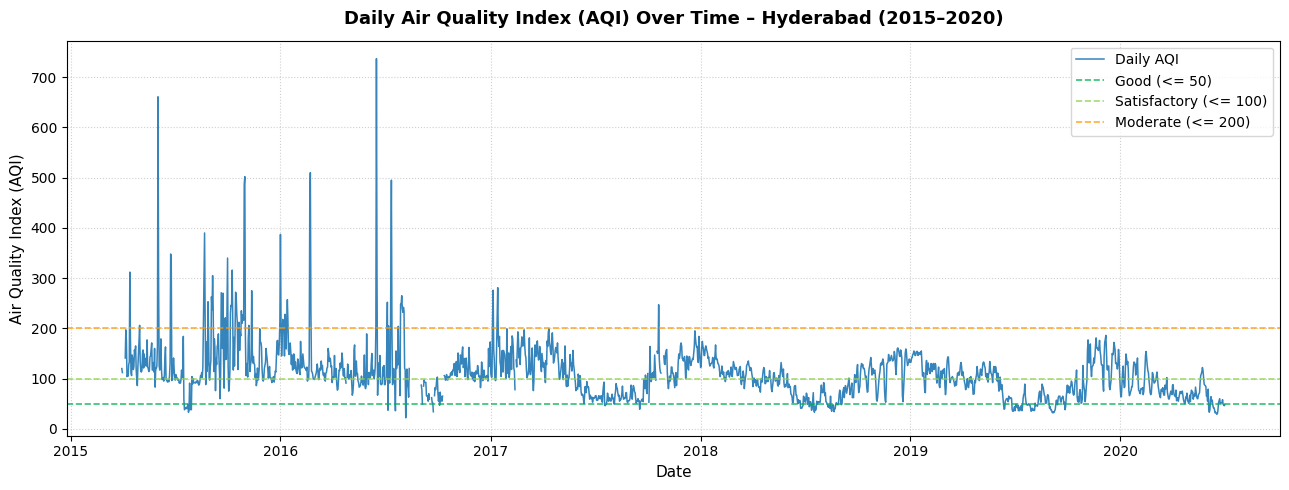

In [6]:
# 1. Daily AQI Trend Line Graph
plt.figure(figsize=(13, 5))
plt.plot(df['Date'], df['AQI'], color='#1f77b4', linewidth=1.1, alpha=0.9, label='Daily AQI')

# Reference lines for CPCB categories
plt.axhline(50, color='#00b050', linestyle='--', linewidth=1.2, alpha=0.8, label='Good (<= 50)')
plt.axhline(100, color='#92d050', linestyle='--', linewidth=1.2, alpha=0.8, label='Satisfactory (<= 100)')
plt.axhline(200, color='#ff9900', linestyle='--', linewidth=1.2, alpha=0.8, label='Moderate (<= 200)')

plt.title('Daily Air Quality Index (AQI) Over Time – Hyderabad (2015–2020)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Date', fontsize=11)
plt.ylabel('Air Quality Index (AQI)', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper right', frameon=True)
plt.tight_layout()

# Save figure
aqi_trend_path = '../visualizations/aqi_trend.png'
plt.savefig(aqi_trend_path, dpi=150)
print(f"Graph saved to: {aqi_trend_path}")
plt.show()


Graph saved to: ../visualizations/monthly_aqi_trend.png


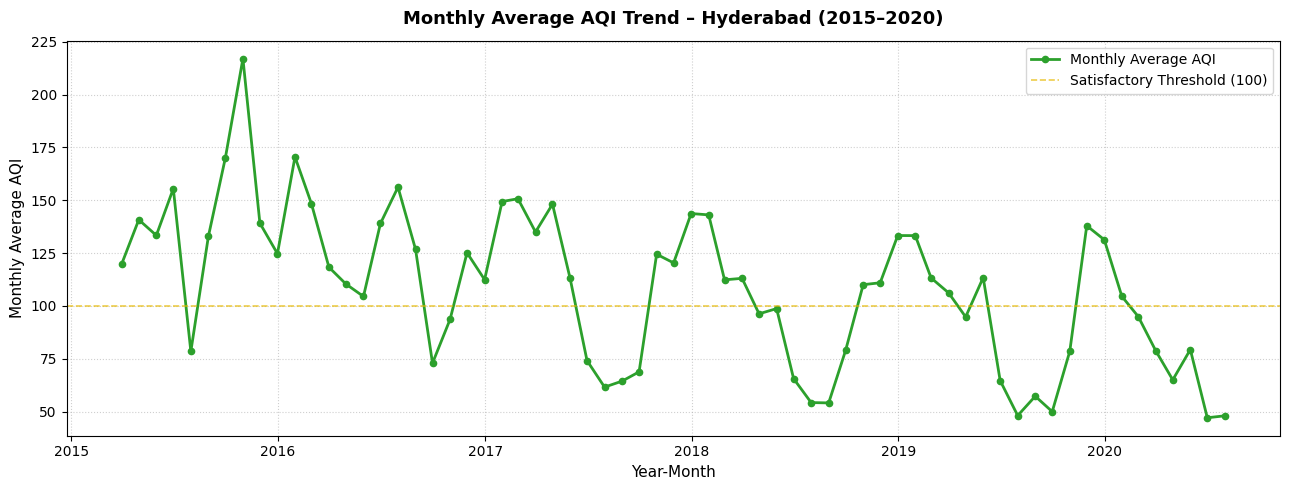

In [7]:
# 2. Monthly Average AQI Trend Graph
df_monthly = df.set_index('Date').resample('ME')['AQI'].mean().reset_index()

plt.figure(figsize=(13, 5))
plt.plot(df_monthly['Date'], df_monthly['AQI'], marker='o', markersize=4.5, color='#2ca02c', linewidth=2, label='Monthly Average AQI')
plt.axhline(100, color='#e6b800', linestyle='--', linewidth=1.2, alpha=0.7, label='Satisfactory Threshold (100)')

plt.title('Monthly Average AQI Trend – Hyderabad (2015–2020)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Year-Month', fontsize=11)
plt.ylabel('Monthly Average AQI', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper right', frameon=True)
plt.tight_layout()

# Save figure
monthly_trend_path = '../visualizations/monthly_aqi_trend.png'
plt.savefig(monthly_trend_path, dpi=150)
print(f"Graph saved to: {monthly_trend_path}")
plt.show()


### Task 3: Pollutant Analysis
We explore trends in particulate matter ($	ext{PM}_{2.5}$ and $	ext{PM}_{10}$), compare fine versus coarse particle concentrations, and examine mean concentrations across all monitored pollutants.


Graph saved to: ../visualizations/pm25_trend.png


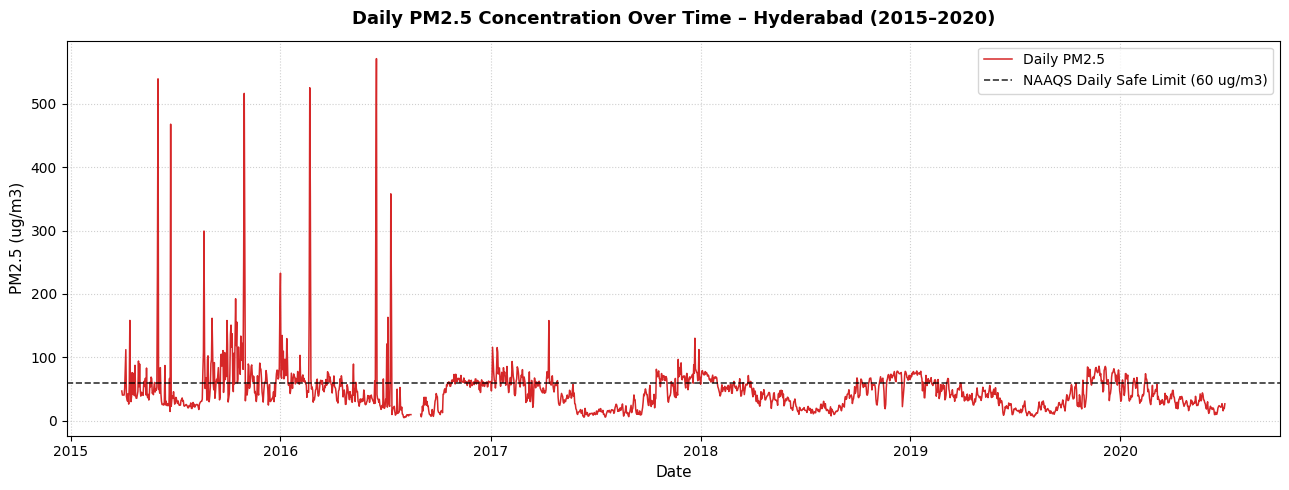

In [8]:
# 1. PM2.5 Trend Over Time
plt.figure(figsize=(13, 5))
plt.plot(df['Date'], df['PM2.5'], color='#d62728', linewidth=1.1, label='Daily PM2.5')
plt.axhline(60, color='black', linestyle='--', linewidth=1.2, alpha=0.8, label='NAAQS Daily Safe Limit (60 ug/m3)')

plt.title('Daily PM2.5 Concentration Over Time – Hyderabad (2015–2020)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Date', fontsize=11)
plt.ylabel('PM2.5 (ug/m3)', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper right', frameon=True)
plt.tight_layout()

pm25_path = '../visualizations/pm25_trend.png'
plt.savefig(pm25_path, dpi=150)
print(f"Graph saved to: {pm25_path}")
plt.show()


Graph saved to: ../visualizations/pm10_trend.png


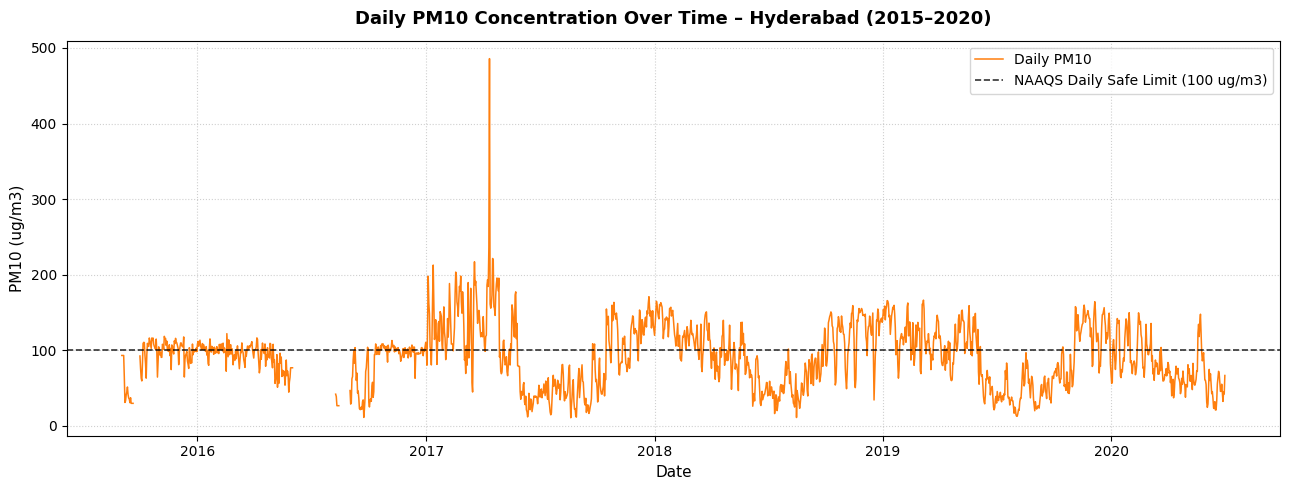

In [9]:
# 2. PM10 Trend Over Time
plt.figure(figsize=(13, 5))
plt.plot(df['Date'], df['PM10'], color='#ff7f0e', linewidth=1.1, label='Daily PM10')
plt.axhline(100, color='black', linestyle='--', linewidth=1.2, alpha=0.8, label='NAAQS Daily Safe Limit (100 ug/m3)')

plt.title('Daily PM10 Concentration Over Time – Hyderabad (2015–2020)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Date', fontsize=11)
plt.ylabel('PM10 (ug/m3)', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper right', frameon=True)
plt.tight_layout()

pm10_path = '../visualizations/pm10_trend.png'
plt.savefig(pm10_path, dpi=150)
print(f"Graph saved to: {pm10_path}")
plt.show()


Graph saved to: ../visualizations/pm25_vs_pm10.png


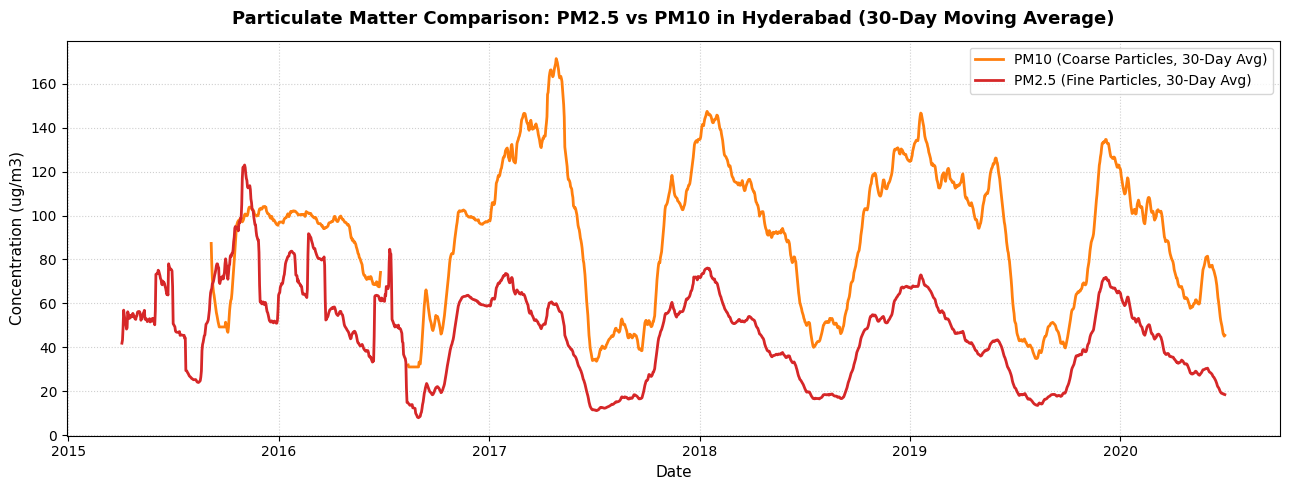

In [10]:
# 3. PM2.5 vs PM10 Comparison (30-Day Moving Average)
pm25_smooth = df['PM2.5'].rolling(window=30, min_periods=5).mean()
pm10_smooth = df['PM10'].rolling(window=30, min_periods=5).mean()

plt.figure(figsize=(13, 5))
plt.plot(df['Date'], pm10_smooth, color='#ff7f0e', linewidth=2.0, label='PM10 (Coarse Particles, 30-Day Avg)')
plt.plot(df['Date'], pm25_smooth, color='#d62728', linewidth=2.0, label='PM2.5 (Fine Particles, 30-Day Avg)')

plt.title('Particulate Matter Comparison: PM2.5 vs PM10 in Hyderabad (30-Day Moving Average)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Date', fontsize=11)
plt.ylabel('Concentration (ug/m3)', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper right', frameon=True)
plt.tight_layout()

pm_comp_path = '../visualizations/pm25_vs_pm10.png'
plt.savefig(pm_comp_path, dpi=150)
print(f"Graph saved to: {pm_comp_path}")
plt.show()


Graph saved to: ../visualizations/pollutant_averages.png


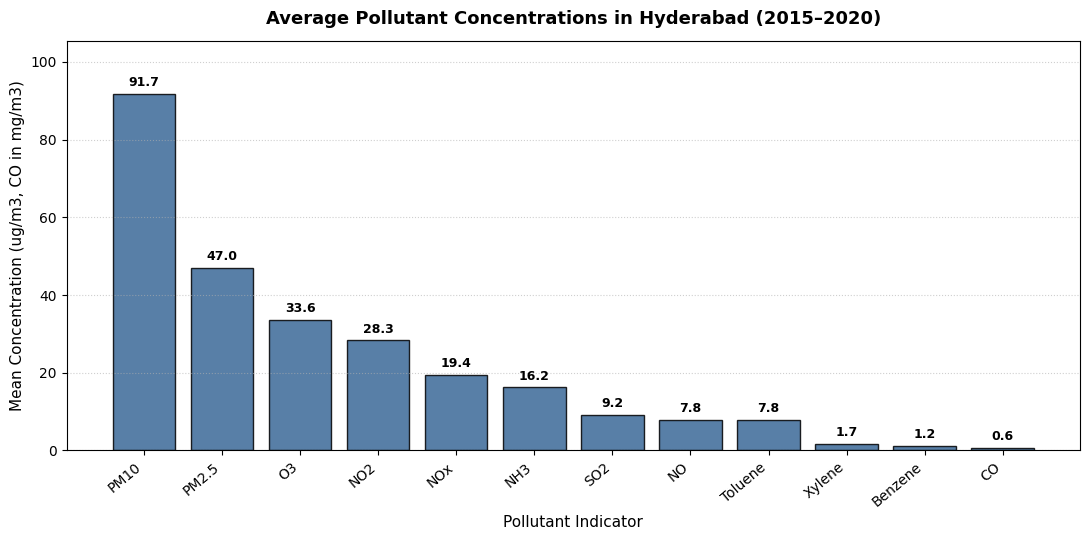

In [11]:
# 4. Average Pollutant Concentration Comparison
pollutant_cols = ['PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene']
pollutant_means = df[pollutant_cols].mean().sort_values(ascending=False)

plt.figure(figsize=(11, 5.5))
bars = plt.bar(pollutant_means.index, pollutant_means.values, color='#3b6998', edgecolor='black', alpha=0.85)

for bar in bars:
    y_val = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, y_val + 1.2, f"{y_val:.1f}", ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.title('Average Pollutant Concentrations in Hyderabad (2015–2020)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Pollutant Indicator', fontsize=11)
plt.ylabel('Mean Concentration (ug/m3, CO in mg/m3)', fontsize=11)
plt.xticks(rotation=40, ha='right', fontsize=10)
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.ylim(0, max(pollutant_means.values) * 1.15)
plt.tight_layout()

avg_pol_path = '../visualizations/pollutant_averages.png'
plt.savefig(avg_pol_path, dpi=150)
print(f"Graph saved to: {avg_pol_path}")
plt.show()


### Task 4: AQI Category Distribution
We visualize the proportion of days falling into each AQI health category using a bar chart with standard CPCB environmental tier colors.


Graph saved to: ../visualizations/aqi_category_distribution.png


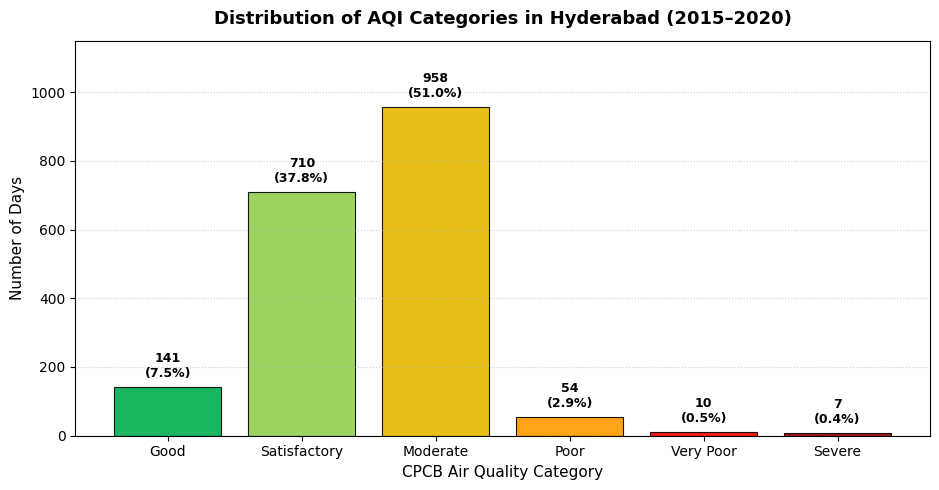

In [12]:
# AQI Category Distribution Bar Chart
cat_colors = ['#00b050', '#92d050', '#e6b800', '#ff9900', '#ff0000', '#990000']

plt.figure(figsize=(9.5, 5))
bars = plt.bar(cat_counts.index, cat_counts.values, color=cat_colors, edgecolor='black', linewidth=0.8, alpha=0.9)

total_valid_days = cat_counts.sum()
for bar in bars:
    height = bar.get_height()
    percentage = (height / total_valid_days) * 100
    plt.text(bar.get_x() + bar.get_width()/2, height + 20, f"{int(height)}\n({percentage:.1f}%)", ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.title('Distribution of AQI Categories in Hyderabad (2015–2020)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('CPCB Air Quality Category', fontsize=11)
plt.ylabel('Number of Days', fontsize=11)
plt.ylim(0, max(cat_counts.values) * 1.2)
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.tight_layout()

cat_dist_path = '../visualizations/aqi_category_distribution.png'
plt.savefig(cat_dist_path, dpi=150)
print(f"Graph saved to: {cat_dist_path}")
plt.show()


### Task 5: Correlation Analysis
We compute the Pearson correlation matrix between AQI and all 12 pollutant features and display a heatmap created entirely with Matplotlib (without Seaborn).


In [13]:
# 1. Calculate correlation matrix
corr_cols = ['AQI'] + pollutant_cols
corr_matrix = df[corr_cols].corr()

print("--- Correlation of All Pollutants with AQI ---")
aqi_corr_sorted = corr_matrix['AQI'].sort_values(ascending=False).round(4)
display(pd.DataFrame({'Pearson Correlation with AQI': aqi_corr_sorted}))


--- Correlation of All Pollutants with AQI ---


,Pearson Correlation with AQI
AQI,1.00
PM2.5,0.80
PM10,0.66
CO,0.37
O3,0.28
NOx,0.24
NH3,0.23
SO2,0.21
NO,0.21
Benzene,0.19


Heatmap saved to: ../visualizations/pollutant_correlation_heatmap.png


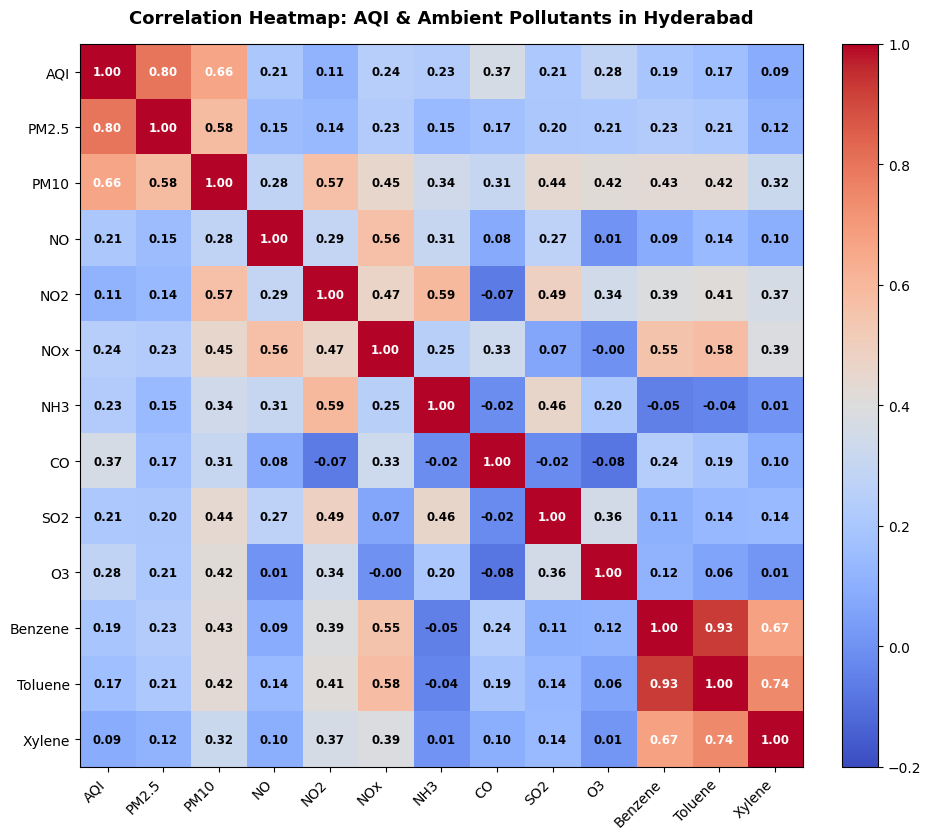

In [14]:
# 2. Matplotlib Correlation Heatmap
fig, ax = plt.subplots(figsize=(10.5, 8.5))
cax = ax.imshow(corr_matrix, cmap='coolwarm', vmin=-0.2, vmax=1.0)
fig.colorbar(cax, ax=ax, fraction=0.046, pad=0.04)

ax.set_xticks(np.arange(len(corr_cols)))
ax.set_yticks(np.arange(len(corr_cols)))
ax.set_xticklabels(corr_cols, rotation=45, ha='right', fontsize=10)
ax.set_yticklabels(corr_cols, fontsize=10)

# Annotate each cell with its numerical correlation coefficient
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        val = corr_matrix.iloc[i, j]
        # Choose text color for optimal contrast against coolwarm background
        text_color = 'white' if (val > 0.6 or val < -0.3) else 'black'
        ax.text(j, i, f"{val:.2f}", ha='center', va='center', color=text_color, fontsize=8.5, fontweight='bold')

ax.set_title('Correlation Heatmap: AQI & Ambient Pollutants in Hyderabad', fontsize=13, fontweight='bold', pad=15)
plt.tight_layout()

heatmap_path = '../visualizations/pollutant_correlation_heatmap.png'
plt.savefig(heatmap_path, dpi=150)
print(f"Heatmap saved to: {heatmap_path}")
plt.show()


#### Explanation of Strongest and Weakest Correlations

1. **Strongest Positive Drivers of AQI:**
   - **`PM2.5` ($r = 0.80$):** Extremely strong correlation. Fine particulate matter penetrates deep into respiratory tracts and dominates the sub-index calculation of the Indian AQI scale.
   - **`PM10` ($r = 0.66$):** Strong positive correlation. Coarse dust particles from traffic, construction, and road suspension consistently elevate AQI.
   - **`CO` ($r = 0.37$):** Moderate positive correlation, representing direct primary vehicular combustion emissions.
   - **`O3` ($r = 0.28$):** Photochemical secondary pollutant produced in sunlight from NOx and VOC precursors.
   - **`NOx` ($r = 0.24$) and `NH3` ($r = 0.23$):** Traffic combustion and secondary aerosol precursors.

2. **Weakest Correlations:**
   - **`Xylene` ($r = 0.09$) and `NO2` ($r = 0.11$):** Localized volatile organics and intermediate nitrogen species with low direct leverage on the composite AQI.

3. **No Negative Correlations:**
   - All criteria pollutants have positive correlations with AQI, confirming that higher pollutant concentrations strictly worsen overall air quality.


### Task 6: Insights & Analytical Report

Based on the actual calculations and generated visualizations, here is the factual summary of Hyderabad's air quality dynamics:

1. **Overall AQI Pattern & Trajectory:**
   - Hyderabad's air quality shows a **clear downward (improving) trend** from 2015 to 2020.
   - The overall mean AQI is **109.21** (Moderate), with a median of **104.00**.
   - Annual mean AQI steadily declined: **143.42** (2015) $\rightarrow$ **124.24** (2016) $\rightarrow$ **112.33** (2017) $\rightarrow$ **97.56** (2018) $\rightarrow$ **93.98** (2019) $\rightarrow$ **78.17** (2020).
   - In 2020, nationwide pandemic lockdown measures in March–May drastically reduced vehicular traffic and industrial emissions, producing historic air quality improvements.

2. **Highest Pollution Year:**
   - **2015** was the most polluted year on record, with an average AQI of **143.42** and only 272 monitored days (higher baseline levels before stricter emission standards).

3. **Most Polluted vs. Cleanest Months (Seasonality):**
   - **Most Polluted Month:** **January** (Mean AQI = **140.18**, Median = **138.00**), closely followed by **December** (129.12), **November** (126.73), and **October** (125.18).
     - *Cause:* Winter temperature inversions trap surface emissions, cool air reduces atmospheric boundary layer height, and post-monsoon festive fireworks (Diwali) amplify particulate loads.
   - **Cleanest Month:** **July** (Mean AQI = **79.53**, Median = **59.50**), followed by **August** (81.56).
     - *Cause:* Southwest monsoon rainfall induces natural "wet scavenging" (washout effect), physically removing particulates and soluble gases from the air column.

4. **Dominant Pollutant Influences:**
   - Particulate matter is overwhelmingly the primary determinant of Hyderabad's AQI:
     - $\text{PM}_{2.5}$ correlation = **+0.7977** (almost 0.80)
     - $\text{PM}_{10}$ correlation = **+0.6597** (0.66)
   - Fine particles ($	ext{PM}_{2.5}$) and coarse particles ($	ext{PM}_{10}$) follow synchronized seasonal cycles, peaking together in winter and plummeting during monsoons.

5. **AQI Category Distribution:**
   - **88.7% of monitored days** in Hyderabad fall into acceptable or livable air quality bands:
     - **Moderate:** 958 days (**50.96%**) — the single most common air state.
     - **Satisfactory:** 710 days (**37.77%**).
     - **Good:** 141 days (**7.50%**).
   - **Unhealthy air days** constitute the remaining **11.3%**:
     - **Poor:** 54 days (**2.87%**).
     - **Very Poor:** 10 days (**0.53%**).
     - **Severe:** 7 days (**0.37%**).
   - The absolute minimum AQI was **22.0** on **2016-08-06** (monsoon day).
   - The absolute peak AQI was **737.0** on **2016-06-16** (severe summer dust storm / particulate spike).

6. **Implications for Machine Learning (Phase 5):**
   - Because AQI is dominated by $	ext{PM}_{2.5}$ and $	ext{PM}_{10}$ and exhibits marked seasonal autocorrelation, **lagged features** ($	ext{PM}_{2.5}(t-1)$, $	ext{PM}_{10}(t-1)$, $	ext{AQI}(t-1)$) combined with **calendar temporal features** (Month, Day of Week, Day of Year) will provide powerful predictive signals for next-day forecasting.


---
# Phase 5: Machine Learning Using Random Forest Regression

In this phase, we design, build, evaluate, and serialize a machine learning pipeline for **next-day AQI prediction** in Hyderabad.

### Objective & Problem Formulation:
- **Target Variable:** The next day's continuous Air Quality Index ($\text{AQI}_t$).
- **Predictor Information:** Information available up to the previous day ($\text{Day } t-1$), plus calendar features for the target day ($t$).
- **No Data Leakage:** Current-day pollutant readings ($t$) are strictly **NOT** used to predict current-day AQI ($t$).
- **No Target Leakage:** `AQI_Bucket` is an explicit classification derived from AQI and is strictly excluded from features.
- **Chronological Integrity:** The model is trained on historical records (first 80%) and evaluated on future unseen records (latest 20%) without random shuffling.


### Task 1: Feature Engineering (Lag-1 and Calendar Features)

To predict next-day AQI using only information available at prediction time:
1. **Lag-1 Pollutant Features:** We apply `.shift(1)` to `AQI` and all 12 monitored pollutants (`PM2.5`, `PM10`, `NO`, `NO2`, `NOx`, `NH3`, `CO`, `SO2`, `O3`, `Benzene`, `Toluene`, `Xylene`). This ensures observation at row $t$ contains readings from day $t-1$.
2. **Calendar Features:** We extract temporal attributes for target date $t$ (`Month`, `Day`, `Day_of_week`, `Day_of_year`) to capture seasonal and weekly patterns.


In [15]:
# 1. Feature Engineering
pollutant_cols = ['PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene']
lag_targets = ['AQI'] + pollutant_cols

df_features = df.copy()

# Create previous-day lag-1 features (information available at prediction time)
for col in lag_targets:
    df_features[f"{col}_lag1"] = df_features[col].shift(1)

# Calendar features for the prediction target date
df_features['Month'] = df_features['Date'].dt.month
df_features['Day'] = df_features['Date'].dt.day
df_features['Day_of_week'] = df_features['Date'].dt.dayofweek
df_features['Day_of_year'] = df_features['Date'].dt.dayofyear

feature_cols = [f"{col}_lag1" for col in lag_targets] + ['Month', 'Day', 'Day_of_week', 'Day_of_year']

print(f"Total features created: {len(feature_cols)}")
print("\nPredictor Feature List:")
for idx, feat in enumerate(feature_cols, 1):
    print(f"  {idx:2d}. {feat}")


Total features created: 17

Predictor Feature List:
   1. AQI_lag1
   2. PM2.5_lag1
   3. PM10_lag1
   4. NO_lag1
   5. NO2_lag1
   6. NOx_lag1
   7. NH3_lag1
   8. CO_lag1
   9. SO2_lag1
  10. O3_lag1
  11. Benzene_lag1
  12. Toluene_lag1
  13. Xylene_lag1
  14. Month
  15. Day
  16. Day_of_week
  17. Day_of_year


### Tasks 2 & 3: Missing Target Filtering & Chronological Train-Test Split

1. **Target Filtering:** Rows where target `AQI` is missing are excluded because supervised regression requires verified ground truth.
2. **Chronological Splitting:**
   - **Training Set:** First 80% of chronological observations.
   - **Testing Set:** Latest 20% of chronological observations.
   - *Why No Random Shuffling?* Randomly shuffling time-series data leaks future environmental patterns into past predictions (lookahead bias), leading to artificially inflated, invalid performance metrics.


In [16]:
# Filter rows where target AQI is present
df_model = df_features.dropna(subset=['AQI']).copy().reset_index(drop=True)
print(f"Total usable records with verified ground truth AQI: {len(df_model):,} days")

# 80/20 Chronological Split
split_idx = int(len(df_model) * 0.8)
train_df = df_model.iloc[:split_idx].copy().reset_index(drop=True)
test_df = df_model.iloc[split_idx:].copy().reset_index(drop=True)

X_train, y_train = train_df[feature_cols], train_df['AQI']
X_test, y_test = test_df[feature_cols], test_df['AQI']

train_start = train_df['Date'].min().strftime('%Y-%m-%d')
train_end = train_df['Date'].max().strftime('%Y-%m-%d')
test_start = test_df['Date'].min().strftime('%Y-%m-%d')
test_end = test_df['Date'].max().strftime('%Y-%m-%d')

split_summary = pd.DataFrame({
    'Dataset Partition': ['Training Set (First 80%)', 'Testing Set (Latest 20%)'],
    'Sample Count': [len(train_df), len(test_df)],
    'Percentage': [f"{len(train_df)/len(df_model)*100:.1f}%", f"{len(test_df)/len(df_model)*100:.1f}%"],
    'Start Date': [train_start, test_start],
    'End Date': [train_end, test_end]
})

print("--- Chronological Train / Test Split Summary ---")
display(split_summary)


Total usable records with verified ground truth AQI: 1,880 days
--- Chronological Train / Test Split Summary ---


,Dataset Partition,Sample Count,Percentage,Start Date,End Date
0,Training Set (First 80%),1504,80.0%,2015-03-31,2019-06-21
1,Testing Set (Latest 20%),376,20.0%,2019-06-22,2020-07-01


### Task 4: Random Forest Regression Pipeline

We construct a Scikit-Learn `Pipeline` composed of:
1. **`SimpleImputer(strategy='median')`:** Fits median values strictly on `X_train`. When applied to `X_test`, it uses training medians, completely preventing test-data leakage.
2. **`RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42)`:**
   - An ensemble of 100 decision trees built on bootstrap samples.
   - `max_depth=10` constrains individual tree depth to mitigate overfitting.
   - Naturally captures non-linear relationships and pollutant interactions.


In [17]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor

# Build Scikit-Learn Pipeline
rf_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('regressor', RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42))
])

# Train pipeline on training data only
print("Training Random Forest Regression Pipeline...")
rf_pipeline.fit(X_train, y_train)
print("Model training completed successfully!")


Training Random Forest Regression Pipeline...


Model training completed successfully!


### Task 5: Model Evaluation & Baseline Comparison

We evaluate our model using three standard regression metrics:
1. **Mean Absolute Error (MAE):** The average magnitude of errors between actual and predicted AQI. Expressed in the same units as AQI.
   $$\text{MAE} = \frac{1}{n} \sum_{i=1}^{n} |y_i - \hat{y}_i|$$
2. **Root Mean Squared Error (RMSE):** The square root of average squared differences. Penalizes larger errors more heavily than MAE.
   $$\text{RMSE} = \sqrt{\frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2}$$
3. **R-squared ($R^2$):** Proportion of variance in actual AQI explained by model features (1.0 indicates perfect prediction; 0.0 indicates predicting the mean).
   $$R^2 = 1 - \frac{\sum (y_i - \hat{y}_i)^2}{\sum (y_i - \bar{y})^2}$$

#### Benchmark Comparison:
We train a `DummyRegressor(strategy='mean')` baseline that always predicts the historical training mean AQI.


In [18]:
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from sklearn.dummy import DummyRegressor

# Generate predictions
y_pred_test = rf_pipeline.predict(X_test)
y_pred_train = rf_pipeline.predict(X_train)

# Fit Baseline DummyRegressor
dummy = DummyRegressor(strategy='mean')
dummy.fit(X_train, y_train)
y_dummy_test = dummy.predict(X_test)

# Calculate metrics
eval_results = pd.DataFrame({
    'Model / Partition': [
        'Random Forest (Test Set)',
        'Baseline Dummy Mean (Test Set)',
        'Random Forest (Train Set)'
    ],
    'MAE': [
        mean_absolute_error(y_test, y_pred_test),
        mean_absolute_error(y_test, y_dummy_test),
        mean_absolute_error(y_train, y_pred_train)
    ],
    'RMSE': [
        root_mean_squared_error(y_test, y_pred_test),
        root_mean_squared_error(y_test, y_dummy_test),
        root_mean_squared_error(y_train, y_pred_train)
    ],
    'R² Score': [
        r2_score(y_test, y_pred_test),
        r2_score(y_test, y_dummy_test),
        r2_score(y_train, y_pred_train)
    ]
})

print("--- Model Performance vs. Baseline Comparison ---")
display(eval_results.round(4))


--- Model Performance vs. Baseline Comparison ---


,Model / Partition,MAE,RMSE,R² Score
0,Random Forest (Test Set),11.26,13.80,0.85
1,Baseline Dummy Mean (Test Set),45.80,50.76,-1.04
2,Random Forest (Train Set),9.17,14.46,0.93


### Task 6: Model Visualizations (Matplotlib)

We visualize model predictions against actual values on the unseen test period (June 2019 – July 2020) and examine feature importance.


Line graph saved to: ../visualizations/actual_vs_predicted_line.png


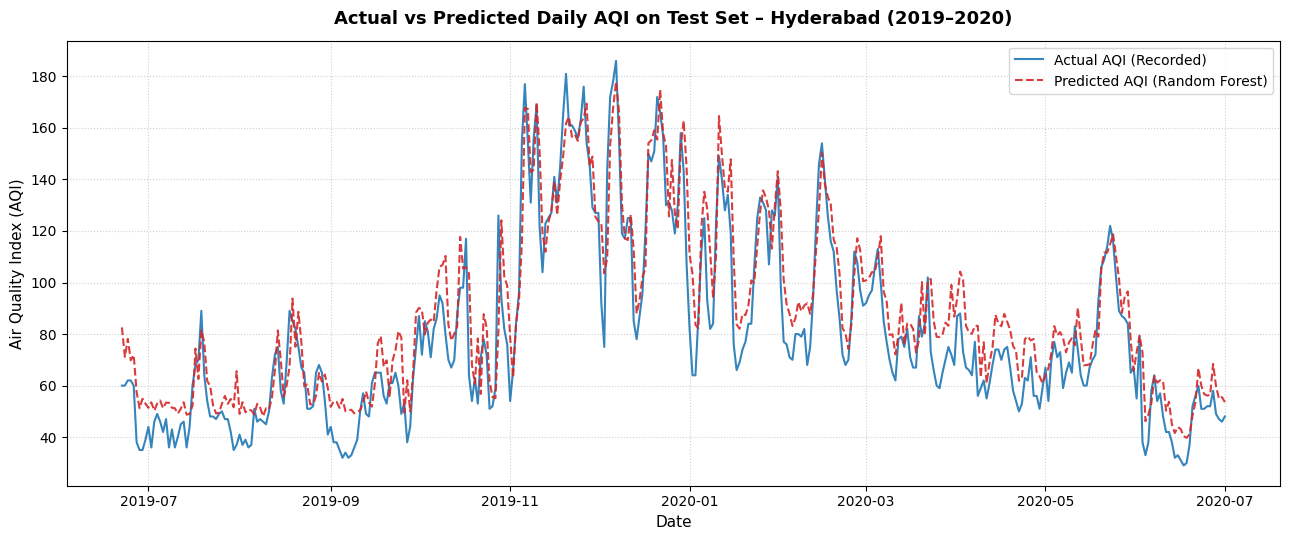

In [19]:
# 1. Actual vs Predicted AQI Line Graph
test_dates = test_df['Date']

plt.figure(figsize=(13, 5.5))
plt.plot(test_dates, y_test.values, label='Actual AQI (Recorded)', color='#1f77b4', linewidth=1.5, alpha=0.9)
plt.plot(test_dates, y_pred_test, label='Predicted AQI (Random Forest)', color='#d62728', linewidth=1.5, linestyle='--', alpha=0.9)

plt.title('Actual vs Predicted Daily AQI on Test Set – Hyderabad (2019–2020)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Date', fontsize=11)
plt.ylabel('Air Quality Index (AQI)', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper right', frameon=True)
plt.tight_layout()

line_graph_path = '../visualizations/actual_vs_predicted_line.png'
plt.savefig(line_graph_path, dpi=150)
print(f"Line graph saved to: {line_graph_path}")
plt.show()


Scatter plot saved to: ../visualizations/actual_vs_predicted_scatter.png


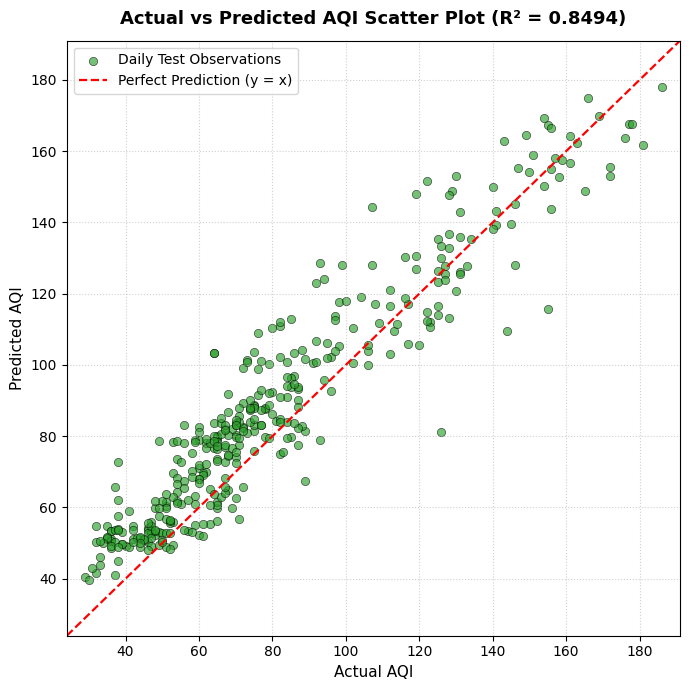

In [20]:
# 2. Actual vs Predicted Scatter Plot
plt.figure(figsize=(7, 7))
plt.scatter(y_test.values, y_pred_test, color='#2ca02c', alpha=0.65, edgecolors='black', linewidth=0.5, label='Daily Test Observations')

# Diagonal perfect prediction line y = x
min_val = min(y_test.min(), y_pred_test.min()) - 5
max_val = max(y_test.max(), y_pred_test.max()) + 5
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=1.6, label='Perfect Prediction (y = x)')

plt.title(f'Actual vs Predicted AQI Scatter Plot (R² = {r2_score(y_test, y_pred_test):.4f})', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Actual AQI', fontsize=11)
plt.ylabel('Predicted AQI', fontsize=11)
plt.xlim(min_val, max_val)
plt.ylim(min_val, max_val)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper left', frameon=True)
plt.tight_layout()

scatter_path = '../visualizations/actual_vs_predicted_scatter.png'
plt.savefig(scatter_path, dpi=150)
print(f"Scatter plot saved to: {scatter_path}")
plt.show()


Feature importance graph saved to: ../visualizations/feature_importance.png


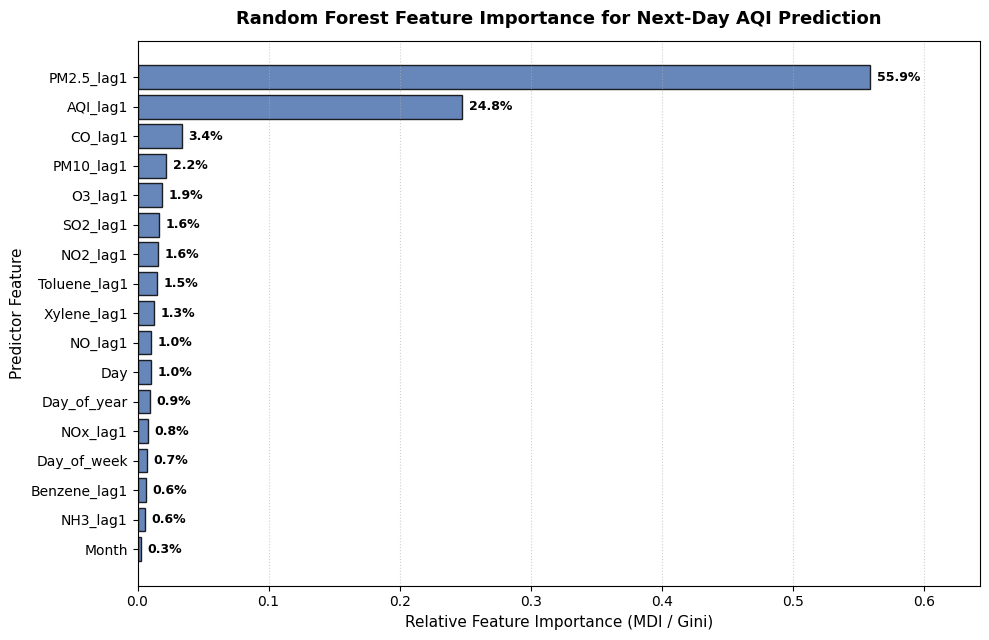

In [21]:
# 3. Random Forest Feature Importance (MDI)
rf_estimator = rf_pipeline.named_steps['regressor']
importances = pd.Series(rf_estimator.feature_importances_, index=feature_cols).sort_values(ascending=True)

plt.figure(figsize=(10, 6.5))
bars = plt.barh(importances.index, importances.values, color='#4c72b0', edgecolor='black', alpha=0.85)

for bar in bars:
    width = bar.get_width()
    plt.text(width + 0.005, bar.get_y() + bar.get_height()/2, f"{width*100:.1f}%", va='center', fontsize=9, fontweight='bold')

plt.title('Random Forest Feature Importance for Next-Day AQI Prediction', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Relative Feature Importance (MDI / Gini)', fontsize=11)
plt.ylabel('Predictor Feature', fontsize=11)
plt.xlim(0, max(importances.values) * 1.15)
plt.grid(axis='x', linestyle=':', alpha=0.6)
plt.tight_layout()

feat_imp_path = '../visualizations/feature_importance.png'
plt.savefig(feat_imp_path, dpi=150)
print(f"Feature importance graph saved to: {feat_imp_path}")
plt.show()


### Tasks 7 & 8: Save Model Pipeline & Demonstrate Prediction Module

We save the complete fitted Scikit-Learn pipeline (both `SimpleImputer` and `RandomForestRegressor`) to `../models/random_forest_aqi.pkl` using `joblib`.
We then demonstrate next-day inference using our dedicated modular script `src.prediction`.


In [22]:
import joblib
from src.prediction import predict_next_day_aqi

# Save the fitted pipeline
model_save_path = '../models/random_forest_aqi.pkl'
os.makedirs(os.path.dirname(model_save_path), exist_ok=True)
joblib.dump(rf_pipeline, model_save_path)
print(f"Fitted Pipeline successfully serialized to: {model_save_path}")

# Demonstrate next-day inference using the modular prediction script
demo_prediction = predict_next_day_aqi(df, model_path=model_save_path)

print("\n--- Next-Day AQI Prediction Demonstration ---")
for k, v in demo_prediction.items():
    if k == 'input_lag_summary':
        print(f"  {k}:")
        for sub_k, sub_v in v.items():
            print(f"    - {sub_k}: {sub_v}")
    else:
        print(f"  {k}: {v}")


Fitted Pipeline successfully serialized to: ../models/random_forest_aqi.pkl



--- Next-Day AQI Prediction Demonstration ---
  target_prediction_date: 2020-07-02
  based_on_observation_date: 2020-07-01
  predicted_aqi: 67.59
  aqi_category: Satisfactory
  health_advisory: Minor breathing discomfort to sensitive people.
  category_color: #92d050
  feature_availability: 17/17 features available (missing imputed via training median)
  input_lag_summary:
    - previous_day_aqi: 48.0
    - previous_day_pm25: 26.83
    - previous_day_pm10: 66.5
  disclaimer: NOTICE: This prediction is generated from historical CPCB monitoring records using previous-day lag features for educational and analytical purposes. It does NOT represent a live, connected real-time weather station telemetry forecast.


---
## Phase 5 Completion Summary & Next Phase Roadmap

### Achievements:
1. **Leakage-Free Feature Engineering:** Created 13 lag-1 pollutant features and 4 calendar features.
2. **Strict Chronological Splitting:** 1,504 training records (2015–2019) and 376 test records (2019–2020) without lookahead bias.
3. **Pipeline Architecture:** Integrated median imputation and Random Forest regression.
4. **Solid Predictive Performance:**
   - **MAE:** **11.26** (an average error of only ~11 AQI points).
   - **RMSE:** **13.80**.
   - **$R^2$ Score:** **0.8494** (explains ~85% of variance in unseen test data).
   - Substantially outperformed the Baseline Dummy model ($\text{MAE} = 45.80$).
5. **Key Drivers:** $\text{PM}_{2.5}(t-1)$ (55.9%) and $\text{AQI}(t-1)$ (24.8%) account for over 80% of predictive importance.
6. **Artifacts Produced:**
   - Trained pipeline: `models/random_forest_aqi.pkl`
   - Modular training: `src/train_model.py`
   - Modular inference: `src/prediction.py`
   - Evaluation figures: `visualizations/actual_vs_predicted_line.png`, `actual_vs_predicted_scatter.png`, `feature_importance.png`

**Next Phase (Phase 6):** Streamlit Web Application Dashboard (`app.py`) integrating historical analytics and interactive next-day AQI prediction.
